<a href="https://colab.research.google.com/github/sanchali-hue/forest-fire-detection-yolov8/blob/main/Forest_Fire_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import os

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU available. Please check your Colab runtime.")


PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [ ]:
from google.colab import drive
import os

# Connect Google Drive
drive.mount('/content/drive')

# Create project folders
PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"

folders = [
    "dataset",
    "checkpoints",
    "results",
    "weights"
]

for folder in folders:
    path = os.path.join(PROJECT_DIR, folder)
    os.makedirs(path, exist_ok=True)
    print("Created:", path)

print("\nGoogle Drive connected!")
print("Project location:", PROJECT_DIR)

Mounted at /content/drive
Created: /content/drive/MyDrive/ForestFireProject/dataset
Created: /content/drive/MyDrive/ForestFireProject/checkpoints
Created: /content/drive/MyDrive/ForestFireProject/results
Created: /content/drive/MyDrive/ForestFireProject/weights

Google Drive connected!
Project location: /content/drive/MyDrive/ForestFireProject


In [ ]:
import os
import torch

# Project directory
PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"

# Check GPU
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not available. Enable it in Runtime > Change runtime type.")

# Create project folders
folders = [
    "dataset",
    "checkpoints",
    "results",
    "weights"
]

for folder in folders:
    path = os.path.join(PROJECT_DIR, folder)
    os.makedirs(path, exist_ok=True)
    print("Ready:", path)

print("\nProject setup complete!")
print("Project location:", PROJECT_DIR)

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4
Ready: /content/drive/MyDrive/ForestFireProject/dataset
Ready: /content/drive/MyDrive/ForestFireProject/checkpoints
Ready: /content/drive/MyDrive/ForestFireProject/results
Ready: /content/drive/MyDrive/ForestFireProject/weights

Project setup complete!
Project location: /content/drive/MyDrive/ForestFireProject


In [ ]:

!pip install -q roboflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 378.3/378.3 kB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 123.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.1 MB/s eta 0:00:00


In [ ]:

import os
from google.colab import drive
from roboflow import Roboflow

# Connect Google Drive
drive.mount('/content/drive')

# Project directory
PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"
DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")

os.makedirs(DATASET_DIR, exist_ok=True)

# Enter your Roboflow API key privately
from getpass import getpass
ROBOFLOW_API_KEY = getpass("Enter your Roboflow API key: ")

# Connect to Roboflow
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

# Select your fire detection dataset
project = rf.workspace("sanchali-shastri").project(
    "fire-dataset-for-yolov8-qalm6-aeaqv"
)

# Download dataset version 1 in YOLOv8 format
version = project.version(1)
dataset = version.download(
    "yolov8",
    location=DATASET_DIR
)

print("\nDataset download complete!")
print("Dataset location:", DATASET_DIR)
print("Dataset path:", dataset.location)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Enter your Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...

Dataset download complete!
Dataset location: /content/drive/MyDrive/ForestFireProject/dataset
Dataset path: /content/drive/MyDrive/ForestFireProject/dataset


In [ ]:

import os

DATASET_DIR = "/content/drive/MyDrive/ForestFireProject/dataset"

print("Checking dataset...\n")

for root, dirs, files in os.walk(DATASET_DIR):
    level = root.replace(DATASET_DIR, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}  {file}")

print("\nDataset verification complete!")

Checking dataset...

dataset/

Dataset verification complete!


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"

print("Searching for dataset files...\n")

for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

    if files:
        print(f"\nFolder: {root}")
        for filename in files[:10]:
            print("  ", filename)

print("\nSearch complete!")

Searching for dataset files...


Search complete!


In [ ]:

%pip install -q ultralytics opencv-python matplotlib pyyaml


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 75.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 9.8 MB/s eta 0:00:00


In [ ]:

import torch
import cv2
import ultralytics
import matplotlib
import yaml
import os

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("OpenCV:", cv2.__version__)
print("Ultralytics:", ultralytics.__version__)
print("Matplotlib:", matplotlib.__version__)

PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"

print("\nProject directory exists:", os.path.isdir(PROJECT_DIR))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

print("\nEnvironment verification complete!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu130
CUDA available: True
OpenCV: 4.14.0
Ultralytics: 8.4.184
Matplotlib: 3.10.0

Project directory exists: True
GPU: Tesla T4

Environment verification complete!


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"
DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")

print("Checking dataset folder...\n")

for root, dirs, files in os.walk(DATASET_DIR):
    level = root.replace(DATASET_DIR, "").count(os.sep)

    # Limit output to the first few directory levels
    if level > 3:
        dirs[:] = []
        continue

    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        file_path = os.path.join(root, file)
        size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"{indent}  {file} ({size_mb:.2f} MB)")

print("\nDataset folder check complete!")

Checking dataset folder...

dataset/

Dataset folder check complete!


In [ ]:
import os

DATASET_DIR = "/content/drive/MyDrive/ForestFireProject/dataset"

print("Does the dataset folder exist?", os.path.exists(DATASET_DIR))
print("Folder contents:", os.listdir(DATASET_DIR))

try:
    print("\nDataset download object:")
    print(dataset)
    print("\nDataset location:")
    print(dataset.location)
except Exception as e:
    print("Dataset variable error:", e)

Does the dataset folder exist? True
Folder contents: []

Dataset download object:

Dataset location:
/content/drive/MyDrive/ForestFireProject/dataset


In [ ]:
import os

DATASET_DIR = "/content/drive/MyDrive/ForestFireProject/dataset"

# Download again and allow overwriting existing files
dataset = version.download(
    model_format="yolov8",
    location=DATASET_DIR,
    overwrite=True
)

print("\nDownload finished.")
print("Dataset location:", dataset.location)
print("\nFiles and folders downloaded:")

for item in os.listdir(DATASET_DIR):
    print(item)

Extracting Dataset Version Zip to /content/drive/MyDrive/ForestFireProject/dataset in yolov8:: 100%|██████████| 7995/7995 [01:12<00:00, 110.56it/s]



Download finished.
Dataset location: /content/drive/MyDrive/ForestFireProject/dataset

Files and folders downloaded:
train
valid
data.yaml
README.roboflow.txt


In [ ]:
import os
import yaml

DATASET_DIR = "/content/drive/MyDrive/ForestFireProject/dataset"

# Read the dataset configuration
yaml_path = os.path.join(DATASET_DIR, "data.yaml")

with open(yaml_path, "r") as f:
    data_config = yaml.safe_load(f)

print("Dataset configuration:")
print(yaml.dump(data_config, sort_keys=False))

# Count images in training and validation folders
for split in ["train", "valid"]:
    split_dir = os.path.join(DATASET_DIR, split)
    image_count = 0

    for root, dirs, files in os.walk(split_dir):
        image_count += sum(
            1 for name in files
            if name.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        )

    print(f"{split.capitalize()} images: {image_count}")

print("\nDataset verification complete!")

Dataset configuration:
names:
- '0'
- fire
nc: 2
roboflow:
  license: CC BY 4.0
  project: fire-dataset-for-yolov8-qalm6-aeaqv
  url: https://app.roboflow.com/sanchali-shastri/fire-dataset-for-yolov8-qalm6-aeaqv/1
  version: 1
  workspace: sanchali-shastri
test: ../test/images
train: ../train/images
val: ../valid/images

Train images: 3196
Valid images: 800

Dataset verification complete!


In [ ]:
import os
import yaml

DATASET_DIR = "/content/drive/MyDrive/ForestFireProject/dataset"

with open(os.path.join(DATASET_DIR, "data.yaml"), "r") as f:
    config = yaml.safe_load(f)

print("Number of classes (nc):", config.get("nc"))
print("Class names:", config.get("names"))

print("\nChecking dataset folders:")
for split in ["train", "valid"]:
    images_dir = os.path.join(DATASET_DIR, split, "images")
    labels_dir = os.path.join(DATASET_DIR, split, "labels")

    print(f"\n{split.upper()}")
    print("Images folder exists:", os.path.isdir(images_dir))
    print("Labels folder exists:", os.path.isdir(labels_dir))

    if os.path.isdir(labels_dir):
        label_files = [
            f for f in os.listdir(labels_dir)
            if f.endswith(".txt")
        ]
        print("Label files:", len(label_files))

print("\nCheck complete!")

Number of classes (nc): 2
Class names: ['0', 'fire']

Checking dataset folders:

TRAIN
Images folder exists: True
Labels folder exists: True
Label files: 3196

VALID
Images folder exists: True
Labels folder exists: True
Label files: 800

Check complete!


In [ ]:
import os
from collections import Counter

DATASET_DIR = "/content/drive/MyDrive/ForestFireProject/dataset"

class_counts = Counter()
invalid_lines = 0
label_files_checked = 0

for split in ["train", "valid"]:
    labels_dir = os.path.join(DATASET_DIR, split, "labels")

    for filename in os.listdir(labels_dir):
        if not filename.endswith(".txt"):
            continue

        label_files_checked += 1
        filepath = os.path.join(labels_dir, filename)

        with open(filepath, "r") as f:
            for line in f:
                parts = line.strip().split()

                if not parts:
                    continue

                try:
                    class_id = int(parts[0])
                    class_counts[class_id] += 1
                except ValueError:
                    invalid_lines += 1

print("Label files checked:", label_files_checked)
print("Object counts by class ID:", dict(sorted(class_counts.items())))
print("Invalid label lines:", invalid_lines)

print("\nCheck complete!")

Label files checked: 3996
Object counts by class ID: {0: 682, 1: 5178}
Invalid label lines: 0

Check complete!


In [ ]:
import os
import yaml

PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"
DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")

# Read the existing dataset configuration
with open(os.path.join(DATASET_DIR, "data.yaml"), "r") as f:
    original_config = yaml.safe_load(f)

# Create a training configuration with absolute paths
training_config = {
    "path": DATASET_DIR,
    "train": "train/images",
    "val": "valid/images",
    "nc": original_config["nc"],
    "names": original_config["names"]
}

# Save the configuration separately, preserving the original
CONFIG_PATH = os.path.join(PROJECT_DIR, "data_train.yaml")

with open(CONFIG_PATH, "w") as f:
    yaml.safe_dump(training_config, f, sort_keys=False)

print("Training configuration created successfully!")
print("\nConfiguration:")
print(yaml.dump(training_config, sort_keys=False))
print("Saved to:", CONFIG_PATH)

Training configuration created successfully!

Configuration:
path: /content/drive/MyDrive/ForestFireProject/dataset
train: train/images
val: valid/images
nc: 2
names:
- '0'
- fire

Saved to: /content/drive/MyDrive/ForestFireProject/data_train.yaml


In [ ]:
from ultralytics import YOLO
import os
import torch

PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"
CONFIG_PATH = os.path.join(PROJECT_DIR, "data_train.yaml")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

# Confirm GPU availability
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Load a pretrained YOLOv8 small model
model = YOLO("yolov8s.pt")

# Train the model
results = model.train(
    data=CONFIG_PATH,
    epochs=20,
    imgsz=640,
    batch=8,
    device=0,
    project=RESULTS_DIR,
    name="forest_fire_yolov8",
    exist_ok=True,
    workers=2,
    plots=True
)

print("\nTraining finished!")
print("Results saved in:", os.path.join(RESULTS_DIR, "forest_fire_yolov8"))

GPU available: True
GPU: Tesla T4
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/ForestFireProject/data_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=

In [ ]:
import os
from ultralytics import YOLO

PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "forest_fire_yolov8",
    "weights",
    "best.pt"
)

print("Model file exists:", os.path.exists(MODEL_PATH))

if os.path.exists(MODEL_PATH):
    model = YOLO(MODEL_PATH)
    print("Model loaded successfully!")
    print("Class names:", model.names)
else:
    print("Model file not found. Check the path.")

Model file exists: True
Model loaded successfully!
Class names: {0: '0', 1: 'fire'}


Testing image: image955_jpg.rf.a25739c90035761cdd8f4c9cc9c1badd.jpg

image 1/1 /content/drive/MyDrive/ForestFireProject/dataset/valid/images/image955_jpg.rf.a25739c90035761cdd8f4c9cc9c1badd.jpg: 640x640 2 fires, 28.9ms
Speed: 2.3ms preprocess, 28.9ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


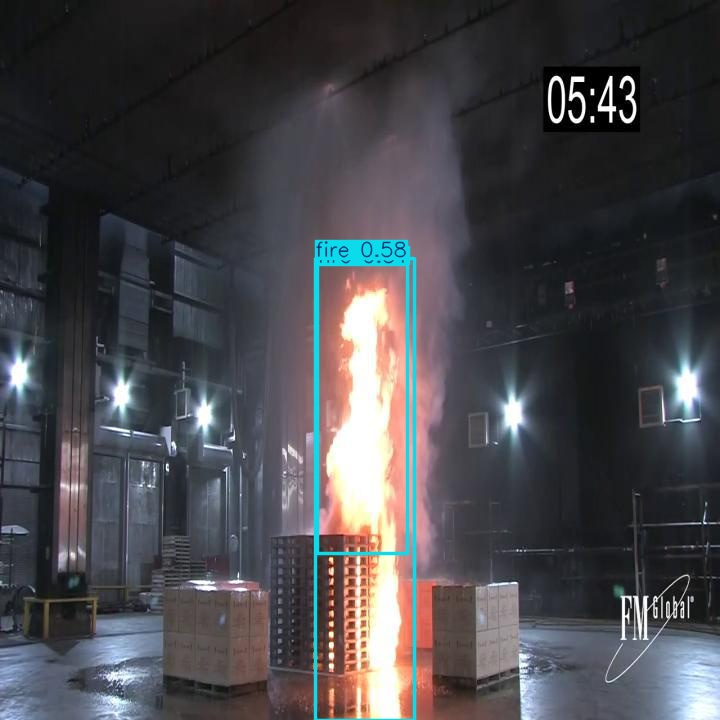

Predicted detections:
Class: fire, Confidence: 0.58
Class: fire, Confidence: 0.51


In [ ]:
import os
import glob
from ultralytics import YOLO
from IPython.display import display, Image

PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "forest_fire_yolov8",
    "weights",
    "best.pt"
)

# Load the trained model
model = YOLO(MODEL_PATH)

# Find an image from the validation dataset
image_files = glob.glob(
    os.path.join(PROJECT_DIR, "dataset", "valid", "images", "*")
)

image_files = [
    f for f in image_files
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

if not image_files:
    print("No validation images found.")
else:
    test_image = image_files[0]
    print("Testing image:", os.path.basename(test_image))

    # Run prediction
    results = model.predict(
        source=test_image,
        conf=0.25,
        save=True
    )

    # Display the image with detection boxes
    output_image = results[0].plot()

    from IPython.display import display
    display(Image(data=__import__("cv2").imencode(
        ".jpg", output_image
    )[1].tobytes()))

    print("Predicted detections:")
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(
            f"Class: {model.names[class_id]}, "
            f"Confidence: {confidence:.2f}"
        )

Saving Raging Flames on the Pine Mountain.png to Raging Flames on the Pine Mountain.png

image 1/1 /content/Raging Flames on the Pine Mountain.png: 448x640 3 fires, 21.1ms
Speed: 2.5ms preprocess, 21.1ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict-2


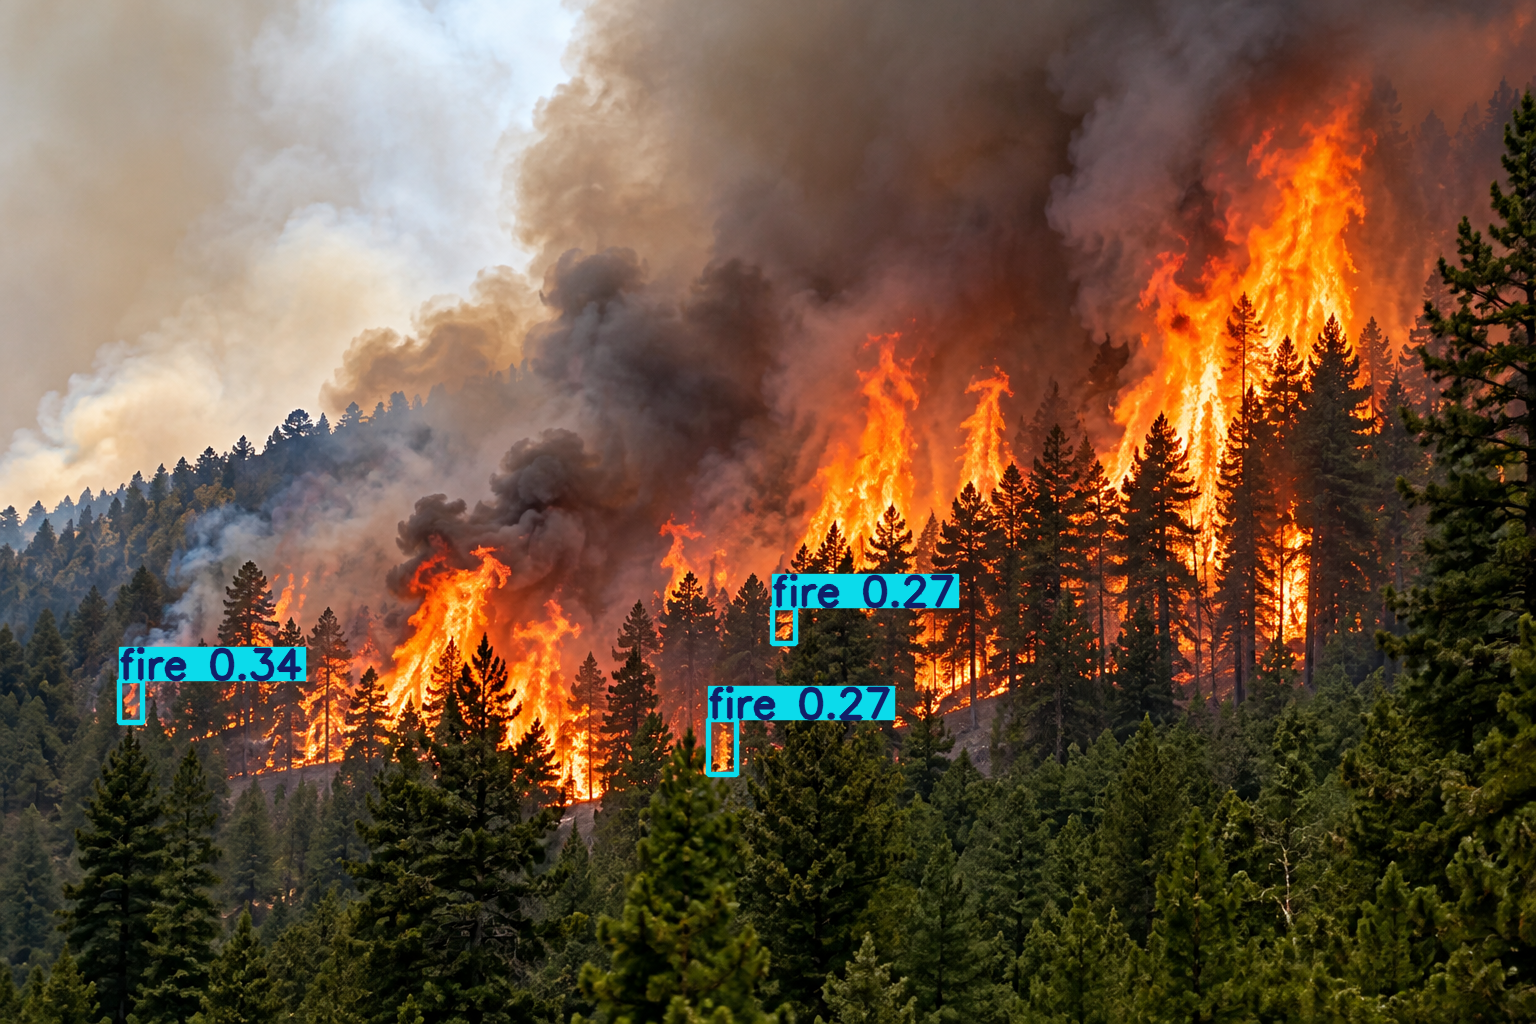


Detection results:
fire: 34.3% confidence
fire: 26.7% confidence
fire: 26.6% confidence


In [ ]:
from google.colab import files
from ultralytics import YOLO
from IPython.display import display
from PIL import Image as PILImage
import os

PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "forest_fire_yolov8",
    "weights",
    "best.pt"
)

# Load your trained model
model = YOLO(MODEL_PATH)

# Upload an image from your computer
uploaded = files.upload()

# Predict on the uploaded image
for filename in uploaded.keys():
    results = model.predict(
        source=filename,
        conf=0.25,
        save=True
    )

    # Display the image with detection boxes
    annotated_image = results[0].plot()
    display(PILImage.fromarray(annotated_image[..., ::-1]))

    # Print detections
    print("\nDetection results:")
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(f"{model.names[class_id]}: {confidence:.1%} confidence")

    if len(results[0].boxes) == 0:
        print("No objects detected.")

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"

print("Project folder exists:", os.path.exists(PROJECT_DIR))

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "forest_fire_yolov8",
    "weights",
    "best.pt"
)

print("Trained model exists:", os.path.exists(MODEL_PATH))

Project folder exists: True
Trained model exists: True


In [3]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ForestFireProject"

for folder, subfolders, files in os.walk(PROJECT_DIR):
    level = folder.replace(PROJECT_DIR, "").count(os.sep)

    if level > 2:
        subfolders[:] = []
        continue

    print("\nFolder:", folder)

    for filename in files[:10]:
        print("  ", filename)


Folder: /content/drive/MyDrive/ForestFireProject
   data_train.yaml

Folder: /content/drive/MyDrive/ForestFireProject/dataset
   README.roboflow.txt
   data.yaml

Folder: /content/drive/MyDrive/ForestFireProject/dataset/train
   labels.cache

Folder: /content/drive/MyDrive/ForestFireProject/dataset/valid
   labels.cache

Folder: /content/drive/MyDrive/ForestFireProject/checkpoints

Folder: /content/drive/MyDrive/ForestFireProject/results

Folder: /content/drive/MyDrive/ForestFireProject/results/forest_fire_yolov8
   args.yaml
   labels.jpg
   train_batch0.jpg
   train_batch1.jpg
   train_batch2.jpg
   train_batch4000.jpg
   train_batch4001.jpg
   train_batch4002.jpg
   val_batch0_labels.jpg
   val_batch0_pred.jpg

Folder: /content/drive/MyDrive/ForestFireProject/weights


In [4]:
from ultralytics import YOLO

MODEL_PATH = "/content/drive/MyDrive/ForestFireProject/results/forest_fire_yolov8/weights/best.pt"

model = YOLO(MODEL_PATH)

print("Model loaded successfully!")
print("Classes:", model.names)

ModuleNotFoundError: No module named 'ultralytics'

In [5]:
!pip install -q ultralytics gradio

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import os

MODEL_PATH = "/content/drive/MyDrive/ForestFireProject/results/forest_fire_yolov8/weights/best.pt"

if os.path.exists(MODEL_PATH):
    print("✅ Trained model found!")
else:
    print("❌ Model not found. We need to locate it.")

✅ Trained model found!


In [8]:
from ultralytics import YOLO

MODEL_PATH = "/content/drive/MyDrive/ForestFireProject/results/forest_fire_yolov8/weights/best.pt"

model = YOLO(MODEL_PATH)

print("🎉 Model loaded successfully!")
print("Model classes:", model.names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
🎉 Model loaded successfully!
Model classes: {0: '0', 1: 'fire'}


In [9]:
demo.launch(share=True, debug=True)

NameError: name 'demo' is not defined

In [ ]:
import gradio as gr
from ultralytics import YOLO
from PIL import Image

# Load your trained model
MODEL_PATH = "/content/drive/MyDrive/ForestFireProject/results/forest_fire_yolov8/weights/best.pt"

model = YOLO(MODEL_PATH)

print("Forest Fire Detection Model Loaded!")


# Fire detection function
def detect_fire(image, confidence):

    if image is None:
        return None, "Please upload an image.", []

    results = model.predict(
        source=image,
        conf=confidence,
        imgsz=640,
        verbose=False
    )

    result = results[0]

    # Create output image with bounding boxes
    annotated = result.plot()[:, :, ::-1]

    # Collect predictions
    detections = []

    for box in result.boxes:
        class_id = int(box.cls[0])
        score = float(box.conf[0])

        detections.append([
            model.names[class_id],
            f"{score:.1%}"
        ])

    # Status message
    if detections:
        status = f"Detection complete! {len(detections)} object(s) detected."
    else:
        status = "No objects detected at this confidence threshold."

    return annotated, status, detections


# Create the frontend
with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown("""
    # 🌲 Forest Fire Detection System
    ### AI-powered fire detection using YOLOv8

    Upload an image to detect possible fire regions.
    """)

    with gr.Row():

        with gr.Column():
            input_image = gr.Image(
                type="pil",
                label="Upload an Image"
            )

            confidence = gr.Slider(
                minimum=0.10,
                maximum=0.90,
                value=0.25,
                step=0.05,
                label="Confidence Threshold"
            )

            detect_button = gr.Button(
                "🔥 Detect Fire",
                variant="primary"
            )

        with gr.Column():
            output_image = gr.Image(
                label="Detection Results"
            )

            status_output = gr.Textbox(
                label="Detection Status"
            )

            results_table = gr.Dataframe(
                headers=["Detected Class", "Confidence"],
                label="Detection Details",
                interactive=False
            )

    detect_button.click(
        fn=detect_fire,
        inputs=[input_image, confidence],
        outputs=[output_image, status_output, results_table]
    )

    gr.Markdown("""
    ---
    **Model:** YOLOv8s | **Training:** 20 epochs

    *Experimental prototype. Predictions may be incorrect.*
    """)


# Launch the frontend
demo.launch(share=True, debug=True)

Forest Fire Detection Model Loaded!


/tmp/ipykernel_565/843232414.py:53: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://8e3027384ba8640e44.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
